In [52]:
import matplotlib.pyplot as plt
import pandas as pd
import pickle

import sys
sys.path.append('../../../')

# Import methods
import QGP.Defocusing.Methods as Def
import QGP.Focusing.Methods as Foc
from QGP.Soliton_Gen import *
from Utilities import *

import config
i = 1j

path = "../../../Heaven_scripts/Results/Blow_up/As/"
path_save = "Img/Heaven/As/"
path_save_local = "Img/Local/"

# Blow up differents A's

In [53]:
As = [0.625, 0.63125, 0.638, 0.64375, 0.65, 0.65625, 0.6609375, 0.665625, 0.6703125, 0.675]
file_names = ["first", "second", "third", "fourth", "fifth"]

norms_inf = []
H1_norms = []
H2_norms = np.full(len(As), fill_value=None)
energies = []
masses = []
times = []

sols_A_1 = []
sols_A_2 = []

for j in range(len(As)):
    file_name = file_names[int(j/2)]
    folder = path + "blow_up_N_160000_Nt_64221_sigma_0.1_{}/".format(file_name)
    folder_name = folder + "blow_up_A_{}/".format(round(As[j], 3))

    H1_file = gzip.GzipFile(folder_name + "H1_norm.npy.gz", "r")
    H1_norms += [np.load(H1_file)]

    #if As[j]!= 0.64375:
    H2_file = gzip.GzipFile(folder_name + "H2_norm.npy.gz", "r")
    H2_norms[j] = np.load(H2_file)

    norm_file = gzip.GzipFile(folder_name + "norm_inf.npy.gz", "r")
    norms_inf += [np.load(norm_file)]

    energy_file = gzip.GzipFile(folder_name + "energy.npy.gz", "r")
    energies += [np.load(energy_file)]

    mass_file = gzip.GzipFile(folder_name + "mass.npy.gz", "r")
    masses += [np.load(mass_file)]

    time_file = gzip.GzipFile(folder_name + "time.npy.gz", "r")
    times += [np.load(time_file)]

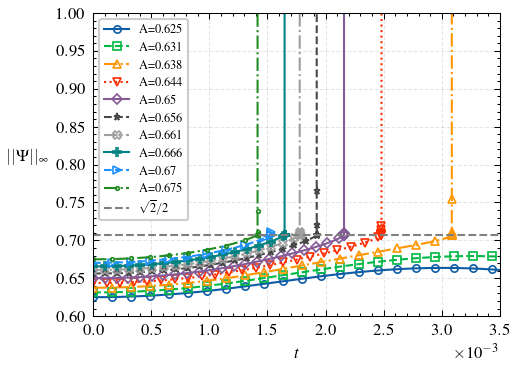

In [44]:
sol_lim = np.sqrt(2)/2

for j in range(len(As)):
    norm_inf_plot = norms_inf[j]
    time_plot = times[j]
    cond = norm_inf_plot!=0
    norm_inf_plot = norm_inf_plot[cond]

    cond_1_markers = np.where(norm_inf_plot<sol_lim)[0]
    mark_indices_1 = cond_1_markers[::3000]
    cond_2_markers = np.where(norm_inf_plot>sol_lim)[0]
    mark_indices_2 = cond_2_markers

    mark_indices = np.append(mark_indices_1, mark_indices_2)
    
    plt.plot(time_plot[cond], norm_inf_plot,label="A={}".format(round(As[j], 3)), markevery=mark_indices, markerfacecolor='none', ms=3.5) #

plt.xlabel(r"$t$")
plt.ylabel(r"$||\Psi||_\infty$", rotation='horizontal', ha='right')
plt.hlines(sol_lim, 0, 3.5e-3, ls="--", color="gray", label=r"$\sqrt{2}/2$")
plt.ylim(0.6, 1)
plt.xlim(0, 3.5e-3)
plt.legend(fontsize=6)
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.savefig(path_save+"Blow_up_As_inf_norm.pdf", dpi=300, bbox_inches = "tight")
#plt.savefig(path_save+"Blow_up_As_inf_norm.pgf", dpi=300, bbox_inches = "tight")
plt.show()

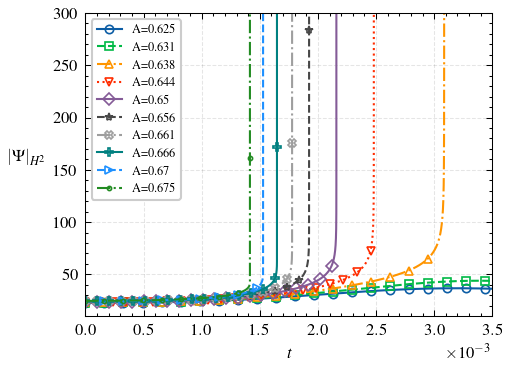

In [43]:
sol_lim = np.sqrt(2)/2+0.000085

for j in range(len(As)):
    #if As[j]!= 0.64375:
    norm_inf = norms_inf[j]
    cond_inf = norm_inf!=0
    norm_inf = norm_inf[cond_inf]

    cond_1_markers = np.where(norm_inf<sol_lim)[0]
    mark_indices_1 = cond_1_markers[::3000]
    cond_2_markers = np.where(norm_inf>sol_lim)[0]
    mark_indices_2 = cond_2_markers
    mark_indices = np.append(mark_indices_1, mark_indices_2)

    H2_norm_plot = H2_norms[j]
    time_plot = times[j]
    cond = H2_norm_plot!=0
    H2_norm_plot = H2_norm_plot[cond]
    plt.plot(time_plot[cond], H2_norm_plot,label="A={}".format(round(As[j], 3)), markevery=mark_indices, markerfacecolor='none') #

plt.xlabel(r"$t$")
plt.ylabel(r"$|\Psi|_{H^2}$", rotation='horizontal', ha='right')
#plt.hlines(np.sqrt(2)/2, 0, 3.5e-3, ls="--", color="gray", label=r"$\sqrt{2}/2$")
plt.ylim(10, 300)
plt.xlim(0, 3.5e-3)
plt.legend(fontsize=6)
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")

plt.savefig(path_save+"Blow_up_As_H2_norm.pdf", dpi=300, bbox_inches = "tight")
#plt.savefig(path_save+"Blow_up_As_H2_norm.pgf", dpi=300, bbox_inches = "tight")
plt.show()

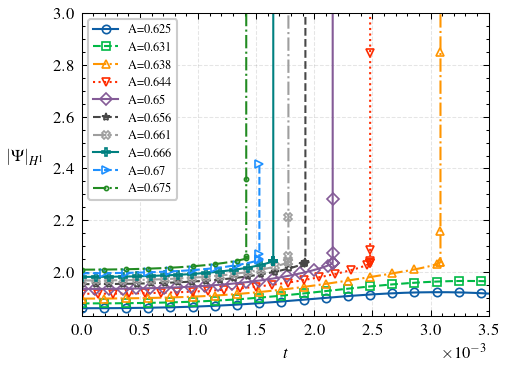

In [44]:
for j in range(len(As)):
    norm_inf = norms_inf[j]
    cond_inf = norm_inf!=0
    norm_inf = norm_inf[cond_inf]

    cond_1_markers = np.where(norm_inf<sol_lim)[0]
    mark_indices_1 = cond_1_markers[::3500]
    cond_2_markers = np.where(norm_inf>sol_lim)[0]
    mark_indices_2 = cond_2_markers
    mark_indices = np.append(mark_indices_1, mark_indices_2)
    
    H1_norm_plot = H1_norms[j]
    time_plot = times[j]
    cond = H1_norm_plot!=0
    plt.plot(time_plot[cond], H1_norm_plot[cond], label="A={}".format(round(As[j], 3)), markevery=mark_indices, markerfacecolor='none')

plt.xlabel(r"$t$")
plt.ylabel(r"$|\Psi|_{H^1}$", rotation='horizontal', ha='right')
#plt.hlines(np.sqrt(2)/2, 0, 3.5e-3, ls="--", color="gray", label=r"$\sqrt{2}/2$")
plt.ylim(1.83, 3)
plt.xlim(0, 3.5e-3)
plt.legend(fontsize=6)
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")

plt.savefig(path_save+"Blow_up_As_H1_norm.pdf", dpi=300, bbox_inches = "tight")
#plt.savefig(path_save+"Blow_up_As_H1_norm.pgf", dpi=300, bbox_inches = "tight")
plt.show()

## $A = 0.65$

In [55]:
L = np.pi
sols = []

A_065_folder = path + "blow_up_N_200000_Nt_64300_sigma_0.1_A_0.65/"
t_file = gzip.GzipFile(A_065_folder + "time.npy.gz", "r")
t = np.load(t_file)

mass_file = gzip.GzipFile(A_065_folder+"mass.npy.gz", "r")
mass = np.load(mass_file)

H1_norm_file = gzip.GzipFile(A_065_folder+"H1_norm.npy.gz", "r")
H1_norm = np.load(H1_norm_file)

H2_norm_file = gzip.GzipFile(A_065_folder+"H2_norm.npy.gz", "r")
H2_norm = np.load(H2_norm_file)

t_file = gzip.GzipFile(A_065_folder+"time.npy.gz", "r")
t = np.load(t_file)

energy_file = gzip.GzipFile(A_065_folder+"energy.npy.gz", "r")
energy = np.load(energy_file)

t_plot = []

N = 200_000
Nt = 64_300

first_N_times = my_lin(0, 64_200, 100, 0.5)[1:-1]
second_N_times = np.arange(64_200, 64_256)
N_times = np.append(first_N_times, second_N_times)

index = 0

for j in range(N_times[-1]-1):
    if (j+2)==N_times[index]:
        sol_file = gzip.GzipFile(A_065_folder + "w_"+f"{j+2:010d}"+".npy.gz", "r")
        sol = np.load(sol_file)
        sols += [sol]
        t_plot += [t[j]]
        index += 1

#sol_file = gzip.GzipFile(folder + "w_0000064256.npy.gz", "r")
#sol = np.load(sol_file)
#sols += [sol]

t_plot = np.array(t_plot)
sols = np.array(sols)
sols = np.stack(sols)

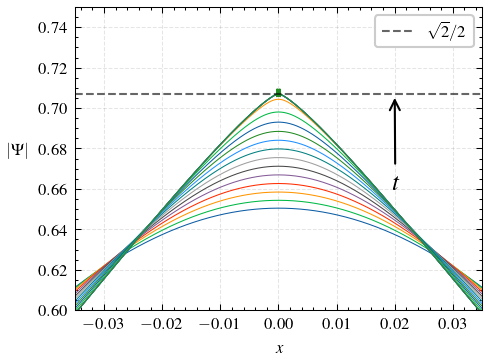

In [46]:
x = np.linspace(-L, L, N)
for j in range(0, len(sols)-1, 8):
    plt.plot(x, np.abs(sols[j]), ls="-", marker="none", lw=.5)

plt.hlines(np.sqrt(2)/2, -0.035, 0.035, ls="--", color="black", alpha=0.6, label=r"$\sqrt{2}/2$")

plt.annotate(
    r'$t$',  # sin texto
    xy=(0.02, np.sqrt(2)/2), xytext=(0.0195, 0.66),
    arrowprops=dict(arrowstyle='->', lw=1),
    xycoords='data',
    fontsize=12
)

plt.legend()
#plt.xlim(-0.3, 0.3)
plt.xlim(-0.035, 0.035)
plt.ylim(0.6, 0.75)

plt.xlabel(r"$x$")
plt.ylabel(r"$|\Psi|$", rotation='horizontal', ha='right')

plt.savefig(path_save+"blow_up_evol_2D.pdf", dpi=300, bbox_inches = "tight")
#plt.savefig(path_save+"blow_up_evol_2D.pgf", dpi=300, bbox_inches = "tight")
plt.show()

In [48]:
s = 0.1
A = 0.65
L = np.pi
x = np.linspace(-L, L, N)

labels = [r"$x$", r"$t$", r"$|\Psi|^2$"]
name_pdf = path_save+"blow_up_sigma_{s}_A_{A}.pdf".format(s=s, A=A)
#name_pgf = path_save+"blow_up_sigma_{s}_A_{A}.pgf".format(s=s, A=A)

#line_plot_3D(sols, x, t_plot, name_pdf, labels, L=0.2, Nt_plot=100, x_rot=-90, z_pad=-27, y_pad=-8, sci=True)
#line_plot_3D(sols, x, t_plot, name_pgf, labels, L=0.2, Nt_plot=100, x_rot=-90, z_pad=-27, y_pad=-8, sci=True)

In [59]:
idx_blow_up = np.where(np.abs(energy - energy[0])>1)[0][0] #np.argmax(np.gradient(energies[j]))
ts_blow = 0.002158186420517196 #t[idx_blow_up]

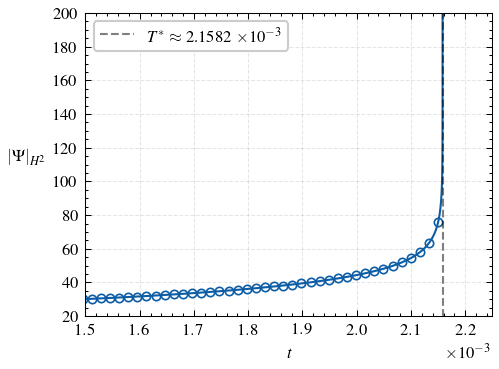

In [60]:
cond = H2_norm!=0
y_upper_lim = 200

plt.plot(t[cond], H2_norm[cond], ls="-", markevery=500, markerfacecolor="none")
plt.vlines(ts_blow, 0, y_upper_lim, ls="--", color="black", alpha=0.5,
           label=r"$T^* \approx $ {}".format(sci_notation(ts_blow, n_decimals=4)))
plt.legend()
#plt.yscale("log")
plt.ylim(20, y_upper_lim)
plt.xlim(1.5e-3, 2.25e-3)
plt.xlabel(r"$t$")
plt.ylabel(r"$|\Psi|_{H^2}$", rotation='horizontal', ha='right')
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")

plt.savefig("Img/Heaven/blow_up_time.pdf", dpi=300, bbox_inches = "tight")
#plt.savefig("Img/Heaven/blow_up_time.pgf", dpi=300, bbox_inches = "tight")
plt.show()

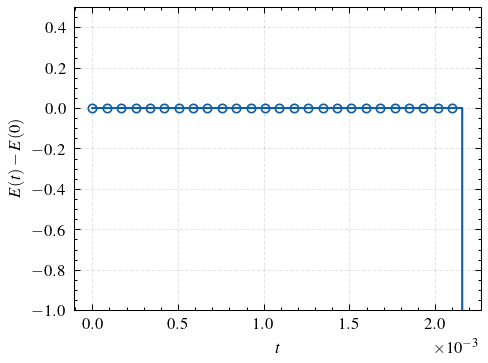

In [11]:
cond = energy!=0
y_upper_lim = 200

plt.plot(t[cond], energy[cond]-energy[0], markevery=2500, markerfacecolor="none")
#plt.vlines(ts_blow, 0, y_upper_lim, ls="--", color="black", alpha=0.5,
#           label=r"$t_b \approx $ {}".format(sci_notation(ts_blow, n_decimals=4)))
#plt.legend()
#plt.yscale("log")
plt.ylim(-1, 0.5)
#plt.xlim(1.5e-3, 2.25e-3)
plt.xlabel(r"$t$")
plt.ylabel(r"$E(t)-E(0)$")
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")

#plt.savefig("Img/Heaven/blow_up_time.pdf", dpi=300, bbox_inches = "tight")
#plt.savefig("Img/Heaven/blow_up_time.pgf", dpi=300, bbox_inches = "tight")
plt.show()

# $A^*$ estimation 

In [2]:
path = "../../../Heaven_scripts/Results/Blow_up/A_est/"
path_sigma_005 = path + "blow_up_A_est_sigma_0.05/"
path_sigma_01 = path + "blow_up_A_est_sigma_0.1/"
path_sigma_02 = path + "blow_up_A_est_sigma_0.2/"
path_sigma_05 = path + "blow_up_A_est_sigma_0.5/"

In [3]:
A_guesses_005_file = gzip.GzipFile(path_sigma_005 + "A_guesses.npy.gz", "r")
A_guesses_005 = np.load(A_guesses_005_file)

A_guesses_01_file = gzip.GzipFile(path_sigma_01 + "A_guesses.npy.gz", "r")
A_guesses_01 = np.load(A_guesses_01_file)

A_guesses_02_file = gzip.GzipFile(path_sigma_02 + "A_guesses.npy.gz", "r")
A_guesses_02 = np.load(A_guesses_02_file)

A_guesses_05_file = gzip.GzipFile(path_sigma_05 + "A_guesses.npy.gz", "r")
A_guesses_05 = np.load(A_guesses_05_file)

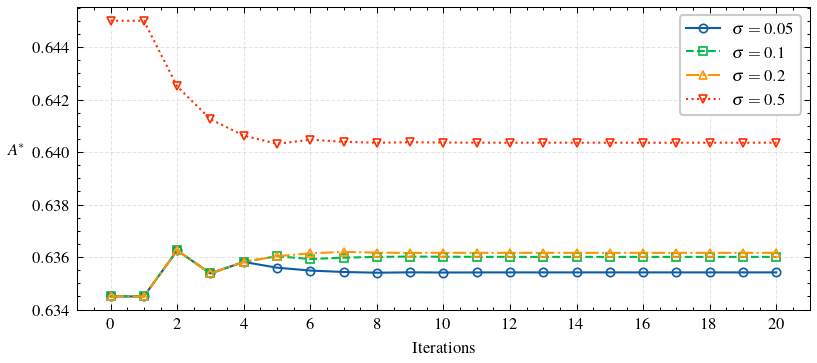

Last iteration value sigma = 0.05:  0.6354139261245728
Last iteration value sigma = 0.1:   0.6360046339035035
Last iteration value sigma = 0.2:   0.6361580286026001
Last iteration value sigma = 0.5:   0.6403541660308838


In [63]:
pt = 1./72.27 # Hundreds of years of history... 72.27 points to an inch.

jour_sizes = {"PRD": {"onecol": 246.*pt, "twocol": 510.*pt},
              "CQG": {"onecol": 374.*pt}, # CQG is only one column
              "DEF": {"onecol": 455.24408*pt}
             }

my_width = jour_sizes["DEF"]["onecol"]
# Our figure's aspect ratio
golden = (1 + 5 ** 0.5) / 2

default_size = plt.rcParams["figure.figsize"]
plt.figure(figsize = (my_width, default_size[1])) #my_width/golden))

plt.plot(A_guesses_005[A_guesses_005!=0], label=r"$\sigma = 0.05$", markerfacecolor="none")
#plt.annotate('%0.5f' % A_guesses_005[A_guesses_005!=0][-1], xy=(1, A_guesses_005[A_guesses_005!=0][-1]), xytext=(3, -3), 
#             xycoords=('axes fraction', 'data'), textcoords='offset points')

plt.plot(A_guesses_01[A_guesses_01!=0], label=r"$\sigma = 0.1$", markerfacecolor="none")
#plt.annotate('%0.5f' % A_guesses_01[A_guesses_01!=0][-1], xy=(1, A_guesses_01[A_guesses_01!=0][-1]), xytext=(3, -3), 
#             xycoords=('axes fraction', 'data'), textcoords='offset points')

plt.plot(A_guesses_02[A_guesses_02!=0], label=r"$\sigma = 0.2$", markerfacecolor="none")
#plt.annotate('%0.5f' % A_guesses_02[A_guesses_02!=0][-1], xy=(1, A_guesses_02[A_guesses_02!=0][-1]), xytext=(3, 1), 
#             xycoords=('axes fraction', 'data'), textcoords='offset points')

plt.plot(A_guesses_05[A_guesses_05!=0], label=r"$\sigma = 0.5$", markerfacecolor="none")
#plt.annotate('%0.5f' % A_guesses_05[A_guesses_05!=0][-1], xy=(1, A_guesses_05[A_guesses_05!=0][-1]), xytext=(3, 0), 
#             xycoords=('axes fraction', 'data'), textcoords='offset points')

plt.legend()
plt.ylabel(r"$A^*$", rotation='horizontal', ha='right')
plt.xlabel("Iterations")
plt.xticks(range(0, 21, 2))

plt.savefig(path_save_local+"Gauss_As/A_est.pdf", dpi=300, bbox_inches = "tight")
#plt.savefig(path_save_local+"Gauss_As/A_est.pgf", bbox_inches = "tight")
plt.show()

print("Last iteration value sigma = 0.05: ", A_guesses_005[A_guesses_005!=0][-1])
print("Last iteration value sigma = 0.1:  ", A_guesses_01[A_guesses_01!=0][-1])
print("Last iteration value sigma = 0.2:  ", A_guesses_02[A_guesses_02!=0][-1])
print("Last iteration value sigma = 0.5:  ", A_guesses_05[A_guesses_05!=0][-1])

In [24]:
A_guesses_005[A_guesses_005!=0]

array([0.6345    , 0.6345    , 0.63625   , 0.635375  , 0.6358125 ,
       0.63559375, 0.63548437, 0.63542969, 0.63540234, 0.63541602,
       0.63540918, 0.6354126 , 0.63541431, 0.63541345, 0.63541388,
       0.63541409, 0.63541399, 0.63541393, 0.63541391, 0.63541392,
       0.63541393])

## $A^*$ test

### $\sigma = 0.1$ without blow up

In [54]:
# No Blow up
eps = 1e-3
A =  A_guesses_01[A_guesses_01!=0][-1] -eps #1 #0.625 #0.65
sigma = 1/10

def gaussian(x, sigma=sigma):
    output = A * np.exp(-x**2/(2 * sigma**2))
    return output

In [28]:
L = np.pi
N = 10_000
k = 1
Nt = 5_000 #10_000
tf = 5e-3
pars = {"k":k}

w_sigma_1_A_nbl = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_sigma_1_A_nbl.set_init_condition(gaussian)
w_sigma_1_A_nbl.solve()#method="fixed point")

Iteration  1  of  5000 . Newton Error:  2.3530198411095314e-15 . Total iteration:  1
Iteration  2  of  5000 . Newton Error:  2.354891406339998e-15 . Total iteration:  1
Iteration  3  of  5000 . Newton Error:  2.3570025001377605e-15 . Total iteration:  1
Iteration  4  of  5000 . Newton Error:  2.3530728952196355e-15 . Total iteration:  1
Iteration  5  of  5000 . Newton Error:  2.35137217697972e-15 . Total iteration:  1
Iteration  6  of  5000 . Newton Error:  2.3560151844528733e-15 . Total iteration:  1
Iteration  7  of  5000 . Newton Error:  2.3537584256832404e-15 . Total iteration:  1
Iteration  8  of  5000 . Newton Error:  2.3514869623231264e-15 . Total iteration:  1
Iteration  9  of  5000 . Newton Error:  2.3529325036169435e-15 . Total iteration:  1
Iteration  10  of  5000 . Newton Error:  2.353123800986429e-15 . Total iteration:  1
Iteration  11  of  5000 . Newton Error:  2.353918449432903e-15 . Total iteration:  1
Iteration  12  of  5000 . Newton Error:  2.352735938352801e-15 . Tot

### $\sigma = 0.1$ with blow up

In [18]:
# No Blow up
eps = 1e-3
A =  A_guesses_01[A_guesses_01!=0][-1] + eps #1 #0.625 #0.65
sigma = 1/10

def gaussian(x, sigma=sigma):
    output = A * np.exp(-x**2/(2 * sigma**2))
    return output

In [19]:
L = np.pi
N = 10_000
k = 1
Nt = 2_000 #10_000
tf = 3.5e-3
pars = {"k":k}

w_sigma_1_A_bl = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_sigma_1_A_bl.set_init_condition(gaussian)
w_sigma_1_A_bl.solve()#method="fixed point")

Iteration  1  of  2000 . Newton Error:  5.934671559254373e-13 . Total iteration:  1
Iteration  2  of  2000 . Newton Error:  5.934693748820622e-13 . Total iteration:  1
Iteration  3  of  2000 . Newton Error:  5.93472681969904e-13 . Total iteration:  1
Iteration  4  of  2000 . Newton Error:  5.934776431082901e-13 . Total iteration:  1
Iteration  5  of  2000 . Newton Error:  5.934848722747457e-13 . Total iteration:  1
Iteration  6  of  2000 . Newton Error:  5.934936130529173e-13 . Total iteration:  1
Iteration  7  of  2000 . Newton Error:  5.935036923775684e-13 . Total iteration:  1
Iteration  8  of  2000 . Newton Error:  5.935149122418579e-13 . Total iteration:  1
Iteration  9  of  2000 . Newton Error:  5.935292504508381e-13 . Total iteration:  1
Iteration  10  of  2000 . Newton Error:  5.935437691572274e-13 . Total iteration:  1
Iteration  11  of  2000 . Newton Error:  5.935605009194371e-13 . Total iteration:  1
Iteration  12  of  2000 . Newton Error:  5.935795334667354e-13 . Total iter

In [20]:
w_sigma_1_A_nbl_max = np_norm(w_sigma_1_A_nbl.w, np.inf, axis=1)
w_sigma_1_A_bl_max = np_norm(w_sigma_1_A_bl.w, np.inf, axis=1)

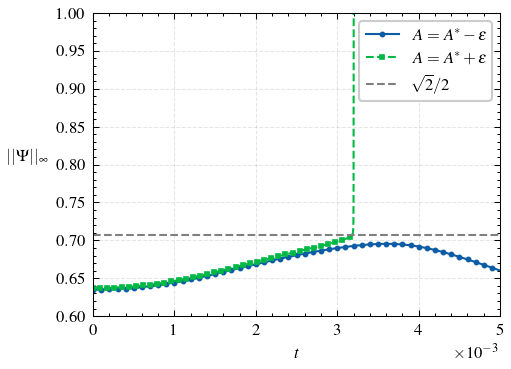

In [55]:
cond_nbl = w_sigma_1_A_nbl_max > 0
cond_bl = w_sigma_1_A_bl_max > 0

plt.plot(w_sigma_1_A_nbl.t[cond_nbl], w_sigma_1_A_nbl_max[cond_nbl], markevery=100, ms=2, label=r"$A = A^* - \varepsilon$")
plt.plot(w_sigma_1_A_bl.t[cond_bl], w_sigma_1_A_bl_max[cond_bl], markevery=50, ms=2, label=r"$A = A^* + \varepsilon$")
plt.hlines(np.sqrt(2)/2, 0, 5e-3, ls="--", color="gray", label=r"$\sqrt{2}/2$")
plt.legend()
plt.ylim(0.6, 1)
plt.ylabel(r"$||\Psi||_\infty$", rotation='horizontal', ha='right')
plt.xlabel(r"$t$")
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.xlim(0, 5e-3)
#plt.xlim(2, 3.8e-3)
plt.savefig(path_save_local+"Gauss_As/Blow_up_A_star_sigma_0_1.pdf", dpi=300, bbox_inches = "tight")
plt.show()

### $\sigma = 0.2$ without blow up

In [22]:
# No Blow up
eps = 1e-3
A =  A_guesses_02[A_guesses_02!=0][-1] -eps #1 #0.625 #0.65
sigma = 2/10

def gaussian(x, sigma=sigma):
    output = A * np.exp(-x**2/(2 * sigma**2))
    return output

In [23]:
L = np.pi
N = 10_000
k = 1
Nt = 5_000 #10_000
tf = 2.5e-2
pars = {"k":k}

w_sigma_2_A_nbl = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_sigma_2_A_nbl.set_init_condition(gaussian)
w_sigma_2_A_nbl.solve()#method="fixed point")

Iteration  1  of  5000 . Newton Error:  2.8794649165283734e-13 . Total iteration:  1
Iteration  2  of  5000 . Newton Error:  2.879448709998738e-13 . Total iteration:  1
Iteration  3  of  5000 . Newton Error:  2.87945116144025e-13 . Total iteration:  1
Iteration  4  of  5000 . Newton Error:  2.879448610699802e-13 . Total iteration:  1
Iteration  5  of  5000 . Newton Error:  2.879505750043307e-13 . Total iteration:  1
Iteration  6  of  5000 . Newton Error:  2.8794977212626906e-13 . Total iteration:  1
Iteration  7  of  5000 . Newton Error:  2.8795819604836837e-13 . Total iteration:  1
Iteration  8  of  5000 . Newton Error:  2.8795526476718307e-13 . Total iteration:  1
Iteration  9  of  5000 . Newton Error:  2.8796064525548657e-13 . Total iteration:  1
Iteration  10  of  5000 . Newton Error:  2.879665267025955e-13 . Total iteration:  1
Iteration  11  of  5000 . Newton Error:  2.879676436938266e-13 . Total iteration:  1
Iteration  12  of  5000 . Newton Error:  2.879727629141571e-13 . Total

### $\sigma = 0.2$ with blow up

In [24]:
# No Blow up
eps = 1e-3
A =  A_guesses_02[A_guesses_02!=0][-1] + eps #1 #0.625 #0.65
sigma = 2/10

def gaussian(x, sigma=sigma):
    output = A * np.exp(-x**2/(2 * sigma**2))
    return output

In [25]:
L = np.pi
N = 10_000
k = 1
Nt = 2_000 #10_000
tf = 2e-2
pars = {"k":k}

w_sigma_2_A_bl = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_sigma_2_A_bl.set_init_condition(gaussian)
w_sigma_2_A_bl.solve()#method="fixed point")

Iteration  1  of  2000 . Newton Error:  2.3330142290059577e-12 . Total iteration:  1
Iteration  2  of  2000 . Newton Error:  2.3330263703546293e-12 . Total iteration:  1
Iteration  3  of  2000 . Newton Error:  2.333051855310804e-12 . Total iteration:  1
Iteration  4  of  2000 . Newton Error:  2.3330990162484078e-12 . Total iteration:  1
Iteration  5  of  2000 . Newton Error:  2.3331591209357414e-12 . Total iteration:  1
Iteration  6  of  2000 . Newton Error:  2.333234658490764e-12 . Total iteration:  1
Iteration  7  of  2000 . Newton Error:  2.3333152586249348e-12 . Total iteration:  1
Iteration  8  of  2000 . Newton Error:  2.3334213465642524e-12 . Total iteration:  1
Iteration  9  of  2000 . Newton Error:  2.3335379783376045e-12 . Total iteration:  1
Iteration  10  of  2000 . Newton Error:  2.3336740017455316e-12 . Total iteration:  1
Iteration  11  of  2000 . Newton Error:  2.3338212816006034e-12 . Total iteration:  1
Iteration  12  of  2000 . Newton Error:  2.3339852169553215e-12 .

In [26]:
w_sigma_2_A_nbl_max = np_norm(w_sigma_2_A_nbl.w, np.inf, axis=1)
w_sigma_2_A_bl_max = np_norm(w_sigma_2_A_bl.w, np.inf, axis=1)

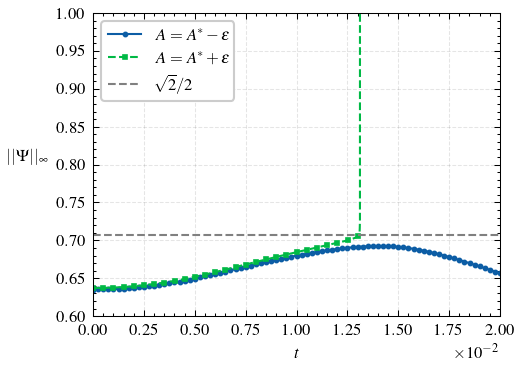

In [56]:
cond_2_nbl = w_sigma_2_A_nbl_max > 0
cond_2_bl = w_sigma_2_A_bl_max > 0

plt.plot(w_sigma_2_A_nbl.t[cond_2_nbl], w_sigma_2_A_nbl_max[cond_2_nbl], markevery=50, ms=2, label=r"$A = A^* - \varepsilon$")
plt.plot(w_sigma_2_A_bl.t[cond_2_bl], w_sigma_2_A_bl_max[cond_2_bl], markevery=50, ms=2, label=r"$A = A^* + \varepsilon$")

plt.hlines(np.sqrt(2)/2, 0, 2e-2, ls="--", color="gray", label=r"$\sqrt{2}/2$")
plt.legend()
plt.ylim(0.6, 1)
plt.ylabel(r"$||\Psi||_\infty$", rotation='horizontal', ha='right')
plt.xlabel(r"$t$")
plt.ticklabel_format(style='sci',scilimits=(-2,4),axis="x")
plt.xlim(0, 2e-2)
#plt.xlim(2, 3.8e-3)
plt.savefig(path_save_local+"Gauss_As/Blow_up_A_star_sigma_0_2.pdf", dpi=300, bbox_inches = "tight")
plt.show()

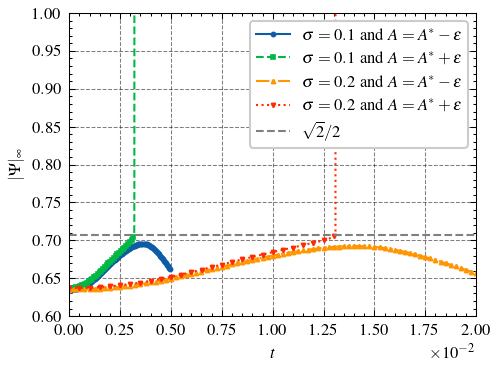

In [82]:
cond_1_nbl = w_sigma_1_A_nbl_max > 0
cond_1_bl = w_sigma_1_A_bl_max > 0

cond_2_nbl = w_sigma_2_A_nbl_max > 0
cond_2_bl = w_sigma_2_A_bl_max > 0

plt.plot(w_sigma_1_A_nbl.t[cond_1_nbl], w_sigma_1_A_nbl_max[cond_1_nbl], markevery=50, ms=2, label=r"$\sigma=0.1$ and $A = A^* - \varepsilon$")
plt.plot(w_sigma_1_A_bl.t[cond_1_bl], w_sigma_1_A_bl_max[cond_1_bl], markevery=50, ms=2, label=r"$\sigma=0.1$ and $A = A^* + \varepsilon$")

plt.plot(w_sigma_2_A_nbl.t[cond_2_nbl], w_sigma_2_A_nbl_max[cond_2_nbl], markevery=50, ms=2, label=r"$\sigma=0.2$ and $A = A^* - \varepsilon$")
plt.plot(w_sigma_2_A_bl.t[cond_2_bl], w_sigma_2_A_bl_max[cond_2_bl], markevery=50, ms=2, label=r"$\sigma=0.2$ and $A = A^* + \varepsilon$")

plt.hlines(np.sqrt(2)/2, 0, 2e-2, ls="--", color="gray", label=r"$\sqrt{2}/2$")
plt.legend()
plt.ylim(0.6, 1)
plt.ylabel(r"$|\Psi|_\infty$")
plt.xlabel(r"$t$")
plt.ticklabel_format(style='sci',scilimits=(-2,4),axis="x")
plt.xlim(0, 2e-2)
#plt.xlim(2, 3.8e-3)
#plt.savefig(path_save_local+"Gauss_As/Blow_up_A_star_sigma_0_2.pdf", dpi=300, bbox_inches = "tight")
plt.show()